### Ebenen: LGS, Skalarprodukt, Ebenengleichungen, Lagebeziehungen - Übungen

In diesem Notebook geht es um **Ebenen im Raum**. Zuerst löst du lineare Gleichungssysteme mit dem **Gauß-Verfahren**,
dann lernst du das **Skalarprodukt** kennen und beschreibst Ebenen in **Parameterform**, **Normalenform** und **Koordinatenform**.
Schließlich untersuchst du, wie Punkte, Geraden und Ebenen zueinander liegen, und berechnest Schnittpunkte und Schnittgeraden.

Vektoren schreibst du wie im Notebook *Geometrie* als Spalten: `Matrix([1, 2, 3])`.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und matplotlib, schaltet die Formel-Ausgabe ein
und legt die Koordinaten `x`, `y`, `z` und die Parameter `r`, `s`, `t` an.

In [ ]:
from sympy import *
init_printing()
import matplotlib.pyplot as plt
x, y, z, r, s, t = symbols('x y z r s t', real=True)

## 1. Lineare Gleichungssysteme und das Gauß-Verfahren

#### Erweiterte Koeffizientenmatrix und Stufenform

Ein LGS wie

x + y + z = 6, 2x − y + z = 3, x + 2y − z = 2

schreibt man als **erweiterte Koeffizientenmatrix**: jede Zeile eine Gleichung, die letzte Spalte die rechte Seite.
Beim **Gauß-Verfahren** formt man die Zeilen um (Vielfache addieren), bis eine Stufenform entsteht.

- `M.rref()` liefert die **reduzierte Stufenform** (und die Nummern der Pivotspalten). Ganz rechts steht dann die Lösung.
- `linsolve(M, [x, y, z])` gibt direkt die Lösungsmenge aus.
- Zeilen umformen von Hand: `M.row(1)` ist die zweite Zeile (Zählung ab 0); `M[1, :] = M.row(1) - 2 * M.row(0)` ersetzt sie.

In [ ]:
M = Matrix([[1, 1, 1, 6], [2, -1, 1, 3], [1, 2, -1, 2]])
display(M)
M2 = M.copy()
M2[1, :] = M2.row(1) - 2 * M2.row(0)
M2[2, :] = M2.row(2) - M2.row(0)
display(M2)
display(M.rref()[0])
linsolve(M, [x, y, z])

#### Drei Fälle

Ein LGS hat **genau eine**, **keine** oder **unendlich viele** Lösungen. In der Stufenform erkennt man:
- eine Zeile 0 0 0 | c mit c ≠ 0: Widerspruch, keine Lösung (`linsolve` gibt ∅)
- eine Nullzeile 0 0 0 | 0: eine Variable ist frei wählbar, unendlich viele Lösungen (`linsolve` gibt die Lösung mit dieser Variablen).

In [ ]:
A = Matrix([[1, 1, 1, 6], [2, 2, 2, 10], [1, -1, 0, 0]])
display(A.rref()[0], linsolve(A, [x, y, z]))
B = Matrix([[1, 1, 1, 6], [2, 2, 2, 12], [1, -1, 0, 0]])
display(B.rref()[0], linsolve(B, [x, y, z]))

#### Aufgabe 1.1

Löse das LGS x + 2y − z = 3, 2x − y + z = 4, x + y + 2z = 5 mit `linsolve` und der erweiterten Matrix.

**Erwartete Ausgabe:**

$\displaystyle \left\{\left( 2, \  1, \  1\right)\right\}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
M = Matrix([[1, 2, -1, 3], [2, -1, 1, 4], [1, 1, 2, 5]])
linsolve(M, [x, y, z])
```

</details>

#### Aufgabe 1.2

Gib die reduzierte Stufenform der Matrix aus der vorigen Aufgabe aus.

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}1 & 0 & 0 & 2\\0 & 1 & 0 & 1\\0 & 0 & 1 & 1\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Matrix([[1, 2, -1, 3], [2, -1, 1, 4], [1, 1, 2, 5]]).rref()[0]
```

</details>

#### Aufgabe 1.3

Führe den ersten Gauß-Schritt von Hand aus: Ziehe für M = [[1, 2, −1, 3], [2, −1, 1, 4], [1, 1, 2, 5]] das 2-Fache der ersten Zeile von der zweiten
und die erste Zeile von der dritten ab. Gib die neue Matrix aus.

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}1 & 2 & -1 & 3\\0 & -5 & 3 & -2\\0 & -1 & 3 & 2\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
M = Matrix([[1, 2, -1, 3], [2, -1, 1, 4], [1, 1, 2, 5]])
M[1, :] = M.row(1) - 2 * M.row(0)
M[2, :] = M.row(2) - M.row(0)
M
```

</details>

#### Aufgabe 1.4

Löse das LGS 2x + y = 1, x − y + z = 2, 3x + z = 3 (auch mit Gleichungen möglich: `linsolve([Eq(...), ...], [x, y, z])`).

**Erwartete Ausgabe:**

$\displaystyle \left\{\left( 1 - \frac{z}{3}, \  \frac{2 z}{3} - 1, \  z\right)\right\}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
linsolve([Eq(2*x + y, 1), Eq(x - y + z, 2), Eq(3*x + z, 3)], [x, y, z])
```

</details>

#### Aufgabe 1.5

Löse das LGS x + y − z = 1, 2x + 2y − 2z = 3, x − y = 0. Gib die Stufenform und die Lösungsmenge aus.

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}1 & 0 & - \frac{1}{2} & 0\\0 & 1 & - \frac{1}{2} & 0\\0 & 0 & 0 & 1\end{matrix}\right]$

$\displaystyle \emptyset$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
M = Matrix([[1, 1, -1, 1], [2, 2, -2, 3], [1, -1, 0, 0]])
display(M.rref()[0])
linsolve(M, [x, y, z])
```

</details>

#### Aufgabe 1.6

Löse das LGS x + y − z = 1, 2x + 2y − 2z = 2, x − y = 0. Gib die Stufenform und die Lösungsmenge aus.

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}1 & 0 & - \frac{1}{2} & \frac{1}{2}\\0 & 1 & - \frac{1}{2} & \frac{1}{2}\\0 & 0 & 0 & 0\end{matrix}\right]$

$\displaystyle \left\{\left( \frac{z}{2} + \frac{1}{2}, \  \frac{z}{2} + \frac{1}{2}, \  z\right)\right\}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
M = Matrix([[1, 1, -1, 1], [2, 2, -2, 2], [1, -1, 0, 0]])
display(M.rref()[0])
linsolve(M, [x, y, z])
```

</details>

#### Aufgabe 1.7

Für welches a hat das LGS x + y = 2, x + a·y = 3 keine Lösung? Berechne dazu die **Determinante** der Koeffizientenmatrix
(`Matrix([[1, 1], [1, a]]).det()`) und löse det = 0. (Ist die Determinante nicht 0, gibt es genau eine Lösung.)

**Erwartete Ausgabe:**

$\displaystyle a - 1$

$\displaystyle \left[ 1\right]$

In [ ]:
a = symbols('a', real=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a = symbols('a', real=True)
d = Matrix([[1, 1], [1, a]]).det()
display(d)
solve(d, a)
```

</details>

#### Aufgabe 1.8

Löse das LGS mit vier Unbekannten: w + x + y + z = 10, w − x = −1, x − y = −1, y − z = −1.

**Erwartete Ausgabe:**

$\displaystyle \left\{\left( 1, \  2, \  3, \  4\right)\right\}$

In [ ]:
w = symbols('w', real=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
w = symbols('w', real=True)
linsolve([Eq(w + x + y + z, 10), Eq(w - x, -1), Eq(x - y, -1), Eq(y - z, -1)], [w, x, y, z])
```

</details>

#### Aufgabe 1.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(linsolve([Eq(x + y, 2), Eq(x - y, 0)], [x, y]))
display(linsolve([Eq(x + y, 2), Eq(2*x + 2*y, 4)], [x, y]))
linsolve([Eq(x + y, 2), Eq(x + y, 3)], [x, y])
```

In [ ]:
display(linsolve([Eq(x + y, 2), Eq(x - y, 0)], [x, y]))
display(linsolve([Eq(x + y, 2), Eq(2*x + 2*y, 4)], [x, y]))
linsolve([Eq(x + y, 2), Eq(x + y, 3)], [x, y])

## 2. Skalarprodukt und Orthogonalität

#### u · v = u₁v₁ + u₂v₂ + u₃v₃

Das **Skalarprodukt** zweier Vektoren ist eine Zahl: `u.dot(v)`. Es gilt:
- u · v = 0 genau dann, wenn u und v **orthogonal** (senkrecht) sind.
- u · u = |u|²

Einen Vektor n, der zu zwei Vektoren u und v orthogonal ist, findet man mit dem LGS n · u = 0, n · v = 0.
Eine Variable ist dabei frei wählbar (es gibt unendlich viele solche Vektoren); man wählt eine einfache Zahl.

In [ ]:
u = Matrix([1, 2, 3])
v = Matrix([2, 0, -1])
display(u.dot(v))
display(Matrix([1, 1, 0]).dot(Matrix([1, -1, 5])))
n1, n2, n3 = symbols('n1 n2 n3', real=True)
n = Matrix([n1, n2, n3])
l = linsolve([n.dot(u), n.dot(v)], [n1, n2, n3])
display(l)
Matrix(list(l)[0]).subs(n3, 2)

#### Aufgabe 2.1

Berechne das Skalarprodukt von u = (2, −1, 4) und v = (3, 2, −1).

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Matrix([2, -1, 4]).dot(Matrix([3, 2, -1]))
```

</details>

#### Aufgabe 2.2

Prüfe, ob u = (1, 2, −2) und v = (4, −1, 1) orthogonal sind.

**Erwartete Ausgabe:**

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Matrix([1, 2, -2]).dot(Matrix([4, -1, 1])) == 0
```

</details>

#### Aufgabe 2.3

Berechne |u|² für u = (2, 3, 6) einmal mit `u.dot(u)` und einmal mit `u.norm()**2`.

**Erwartete Ausgabe:**

$\displaystyle 49$

$\displaystyle 49$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
u = Matrix([2, 3, 6])
display(u.dot(u))
u.norm()**2
```

</details>

#### Aufgabe 2.4

Für welches a sind u = (a, 2, 1) und v = (3, a, −4) orthogonal?

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{4}{5}\right]$

In [ ]:
a = symbols('a', real=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a = symbols('a', real=True)
solve(Matrix([a, 2, 1]).dot(Matrix([3, a, -4])), a)
```

</details>

#### Aufgabe 2.5

Bestimme einen Vektor n, der zu u = (1, 0, 2) und v = (0, 1, −1) orthogonal ist (wie im Beispiel, setze dann n3 = 1).

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}-2\\1\\1\end{matrix}\right]$

In [ ]:
n1, n2, n3 = symbols('n1 n2 n3', real=True)
n = Matrix([n1, n2, n3])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
n1, n2, n3 = symbols('n1 n2 n3', real=True)
n = Matrix([n1, n2, n3])
l = linsolve([n.dot(Matrix([1, 0, 2])), n.dot(Matrix([0, 1, -1]))], [n1, n2, n3])
Matrix(list(l)[0]).subs(n3, 1)
```

</details>

#### Aufgabe 2.6

**(Leistungsfach)** Das **Vektorprodukt** u × v (`u.cross(v)`) ist immer zu u und v orthogonal. Berechne es für u = (1, 0, 2), v = (0, 1, −1)
und prüfe mit dem Skalarprodukt, dass es zu u und v orthogonal ist.

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}-2\\1\\1\end{matrix}\right]$

$\displaystyle \left( 0, \  0\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
u, v = Matrix([1, 0, 2]), Matrix([0, 1, -1])
n = u.cross(v)
display(n)
(n.dot(u), n.dot(v))
```

</details>

#### Aufgabe 2.7

Prüfe, ob das Dreieck A(1 | 0 | 0), B(3 | 2 | 1), C(0 | 2 | 2) bei A einen rechten Winkel hat (Skalarprodukt von AB und AC).

**Erwartete Ausgabe:**

$\displaystyle 4$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
A, B, C = Matrix([1, 0, 0]), Matrix([3, 2, 1]), Matrix([0, 2, 2])
(B - A).dot(C - A)
```

</details>

#### Aufgabe 2.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
u = Matrix([1, 0, 0])
v = Matrix([0, 5, 0])
display(u.dot(v))
display(u.dot(u))
display(v.dot(v))
(2 * u).dot(v + u)
```

In [ ]:
u = Matrix([1, 0, 0])
v = Matrix([0, 5, 0])
display(u.dot(v))
display(u.dot(u))
display(v.dot(v))
(2 * u).dot(v + u)

## 3. Ebenen in Parameterform

#### E: x⃗ = p⃗ + r · u⃗ + s · v⃗

Eine Ebene ist festgelegt durch einen **Stützpunkt** P und zwei **Spannvektoren** u, v, die nicht kollinear sind.
Jeder Punkt der Ebene ergibt sich für passende Werte der Parameter r und s.

Ebene durch drei Punkte A, B, C: Stützvektor A, Spannvektoren AB und AC.

**Punktprobe:** Liegt Q in E? Löse p + r·u + s·v = q nach r und s (drei Gleichungen, zwei Unbekannte).

In [ ]:
P = Matrix([1, 0, 2])
u = Matrix([1, 1, 0])
v = Matrix([0, 1, 1])
E = P + r * u + s * v
display(E)
display(E.subs({r: 2, s: -1}))
display(solve(list(E - Matrix([3, 3, 3])), [r, s]))
solve(list(E - Matrix([3, 3, 4])), [r, s])

#### Aufgabe 3.1

Gib für die Ebene E aus dem Beispiel die Punkte für (r, s) = (0, 0), (1, 0) und (1, 1) als Liste aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ \left[ 1, \  0, \  2\right], \  \left[ 2, \  1, \  2\right], \  \left[ 2, \  2, \  3\right]\right]$

In [ ]:
E = Matrix([1, 0, 2]) + r * Matrix([1, 1, 0]) + s * Matrix([0, 1, 1])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
E = Matrix([1, 0, 2]) + r * Matrix([1, 1, 0]) + s * Matrix([0, 1, 1])
[list(E.subs({r: a, s: b})) for a, b in [(0, 0), (1, 0), (1, 1)]]
```

</details>

#### Aufgabe 3.2

Prüfe, ob Q(0 | −2 | 0) in E liegt.

**Erwartete Ausgabe:**

$\displaystyle \left[ \right]$

In [ ]:
E = Matrix([1, 0, 2]) + r * Matrix([1, 1, 0]) + s * Matrix([0, 1, 1])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
E = Matrix([1, 0, 2]) + r * Matrix([1, 1, 0]) + s * Matrix([0, 1, 1])
solve(list(E - Matrix([0, -2, 0])), [r, s])
```

</details>

#### Aufgabe 3.3

Prüfe, ob Q(2 | 4 | 5) in E liegt.

**Erwartete Ausgabe:**

$\displaystyle \left\{ r : 1, \  s : 3\right\}$

In [ ]:
E = Matrix([1, 0, 2]) + r * Matrix([1, 1, 0]) + s * Matrix([0, 1, 1])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
E = Matrix([1, 0, 2]) + r * Matrix([1, 1, 0]) + s * Matrix([0, 1, 1])
solve(list(E - Matrix([2, 4, 5])), [r, s])
```

</details>

#### Aufgabe 3.4

Gib eine Parameterform der Ebene durch A(1 | 2 | 0), B(3 | 0 | 1) und C(0 | 1 | 4) aus.

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}2 r - s + 1\\- 2 r - s + 2\\r + 4 s\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
A, B, C = Matrix([1, 2, 0]), Matrix([3, 0, 1]), Matrix([0, 1, 4])
A + r * (B - A) + s * (C - A)
```

</details>

#### Aufgabe 3.5

Liegen die Punkte A(1 | 1 | 1), B(2 | 3 | 1) und C(4 | 7 | 1) so, dass sie eine Ebene festlegen? Prüfe, ob AB und AC kollinear sind (Kreuzprodukt).

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}0\\0\\0\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
A, B, C = Matrix([1, 1, 1]), Matrix([2, 3, 1]), Matrix([4, 7, 1])
(B - A).cross(C - A)
```

</details>

#### Aufgabe 3.6

Für welches a liegt Q(a | 3 | 4) in der Ebene E aus dem Beispiel? Löse nach r, s und a.

**Erwartete Ausgabe:**

$\displaystyle \left\{ a : 2, \  r : 1, \  s : 2\right\}$

In [ ]:
E = Matrix([1, 0, 2]) + r * Matrix([1, 1, 0]) + s * Matrix([0, 1, 1])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
E = Matrix([1, 0, 2]) + r * Matrix([1, 1, 0]) + s * Matrix([0, 1, 1])
a = symbols('a', real=True)
solve(list(E - Matrix([a, 3, 4])), [r, s, a])
```

</details>

## 4. Normalenform und Koordinatenform

#### n⃗ · (x⃗ − p⃗) = 0 und ax + by + cz = d

Ein **Normalenvektor** n steht senkrecht auf der Ebene. Ein Punkt X liegt genau dann in E, wenn X − P orthogonal zu n ist:
**Normalenform** n · (x − p) = 0. Multipliziert man aus, entsteht die **Koordinatenform** n₁x + n₂y + n₃z = d.
Die Koeffizienten vor x, y, z sind der Normalenvektor.

Von der Parameterform zur Koordinatenform: Normalenvektor bestimmen (LGS wie in Abschnitt 2 oder im Leistungsfach mit dem Vektorprodukt),
dann d = n · p.

`Plane(Point3D(...), normal_vector=(...))` ist eine sympy-Ebene; `.equation(x, y, z)` gibt die Koordinatenform als Term ... = 0 aus.

In [ ]:
P = Matrix([1, 0, 2])
n = Matrix([1, -1, 1])
X = Matrix([x, y, z])
display(expand(n.dot(X - P)))
display(Eq(n.dot(X), n.dot(P)))
E = Plane(Point3D(1, 0, 2), normal_vector=(1, -1, 1))
display(E.equation(x, y, z))
Plane(Point3D(1, 0, 0), Point3D(0, 2, 0), Point3D(0, 0, 3)).equation(x, y, z)

#### Aufgabe 4.1

Gib die Koordinatenform der Ebene durch P(2 | 1 | −1) mit dem Normalenvektor n = (3, −2, 1) aus (als `Eq`).

**Erwartete Ausgabe:**

$\displaystyle 3 x - 2 y + z = 3$

In [ ]:
X = Matrix([x, y, z])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Matrix([x, y, z])
n, P = Matrix([3, -2, 1]), Matrix([2, 1, -1])
Eq(n.dot(X), n.dot(P))
```

</details>

#### Aufgabe 4.2

Prüfe, ob die Punkte Q(1 | 1 | 1) und R(0 | 0 | 3) in der Ebene E: 3x − 2y + z = 3 liegen (zwei Wahrheitswerte).

**Erwartete Ausgabe:**

$\displaystyle \text{False}$

$\displaystyle \text{True}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
ebene = Eq(3*x - 2*y + z, 3)
display(ebene.subs({x: 1, y: 1, z: 1}))
ebene.subs({x: 0, y: 0, z: 3})
```

</details>

#### Aufgabe 4.3

Wandle die Parameterform E: x = (1, 0, 2) + r · (1, 1, 0) + s · (0, 1, 1) in Koordinatenform um. Bestimme n mit dem LGS (n3 = 1) und dann d.

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}1\\-1\\1\end{matrix}\right]$

$\displaystyle x - y + z = 3$

In [ ]:
n1, n2, n3 = symbols('n1 n2 n3', real=True)
n = Matrix([n1, n2, n3])
X = Matrix([x, y, z])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
n1, n2, n3 = symbols('n1 n2 n3', real=True)
n = Matrix([n1, n2, n3])
X = Matrix([x, y, z])
l = linsolve([n.dot(Matrix([1, 1, 0])), n.dot(Matrix([0, 1, 1]))], [n1, n2, n3])
nv = Matrix(list(l)[0]).subs(n3, 1)
display(nv)
Eq(nv.dot(X), nv.dot(Matrix([1, 0, 2])))
```

</details>

#### Aufgabe 4.4

**(Leistungsfach)** Dieselbe Umwandlung mit dem Vektorprodukt: n = u × v, dann d = n · p.

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}1\\-1\\1\end{matrix}\right]$

$\displaystyle x - y + z = 3$

In [ ]:
X = Matrix([x, y, z])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Matrix([x, y, z])
n = Matrix([1, 1, 0]).cross(Matrix([0, 1, 1]))
display(n)
Eq(n.dot(X), n.dot(Matrix([1, 0, 2])))
```

</details>

#### Aufgabe 4.5

Gib die Koordinatenform der Ebene durch A(1 | 2 | 0), B(3 | 0 | 1) und C(0 | 1 | 4) mit `Plane(...).equation(x, y, z)` aus.

**Erwartete Ausgabe:**

$\displaystyle - 7 x - 9 y - 4 z + 25$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Plane(Point3D(1, 2, 0), Point3D(3, 0, 1), Point3D(0, 1, 4)).equation(x, y, z)
```

</details>

#### Aufgabe 4.6

Gib einen Normalenvektor und einen Punkt der Ebene E: 2x + y − 3z = 6 aus (einen Punkt findest du z. B. mit y = z = 0).

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}2\\1\\-3\end{matrix}\right]$

$\displaystyle \left[ 3\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(Matrix([2, 1, -3]))
solve(Eq(2*x, 6), x)
```

</details>

#### Aufgabe 4.7

Wandle die Koordinatenform E: x + 2y − z = 4 in eine Parameterform um: Löse die Gleichung nach x auf, setze y = r und z = s.

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}- 2 r + s + 4\\r\\s\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
xr = solve(Eq(x + 2*y - z, 4), x)[0]
Matrix([xr, y, z]).subs({y: r, z: s})
```

</details>

#### Aufgabe 4.8

Gib die Koordinatenform der Ebene, die durch P(1 | 1 | 1) geht und zur Ebene 2x − y + 2z = 7 parallel ist, aus (gleicher Normalenvektor).

**Erwartete Ausgabe:**

$\displaystyle 2 x - y + 2 z = 3$

In [ ]:
X = Matrix([x, y, z])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Matrix([x, y, z])
n = Matrix([2, -1, 2])
Eq(n.dot(X), n.dot(Matrix([1, 1, 1])))
```

</details>

#### Aufgabe 4.9

Gib die Koordinatenform der Ebene aus, die durch P(0 | 2 | 1) geht und senkrecht zur Geraden g: x = (1, 0, 0) + t · (1, 2, −2) steht.

**Erwartete Ausgabe:**

$\displaystyle x + 2 y - 2 z = 2$

In [ ]:
X = Matrix([x, y, z])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
X = Matrix([x, y, z])
n = Matrix([1, 2, -2])
Eq(n.dot(X), n.dot(Matrix([0, 2, 1])))
```

</details>

#### Aufgabe 4.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
E = Eq(x + y + z, 3)
display(E.subs({x: 1, y: 1, z: 1}))
display(E.subs({x: 3, y: 0, z: 0}))
E.subs({x: 1, y: 2, z: 3})
```

In [ ]:
E = Eq(x + y + z, 3)
display(E.subs({x: 1, y: 1, z: 1}))
display(E.subs({x: 3, y: 0, z: 0}))
E.subs({x: 1, y: 2, z: 3})

## 5. Spurpunkte und Darstellung

#### Schnittpunkte mit den Koordinatenachsen

Die **Spurpunkte** einer Ebene sind ihre Schnittpunkte mit den Koordinatenachsen. Für die x₁-Achse setzt man y = z = 0 usw.
Mit den Spurpunkten kann man die Ebene als Dreieck im Koordinatensystem zeichnen.

`plot3d` zeichnet eine Ebene, die man nach z auflösen kann, als Fläche. Es muss extra geladen werden: `from sympy.plotting import plot3d`.

In [ ]:
ebene = 6*x + 3*y + 2*z - 6
display(solve(ebene.subs({y: 0, z: 0}), x))
display(solve(ebene.subs({x: 0, z: 0}), y))
display(solve(ebene.subs({x: 0, y: 0}), z))
zf = solve(ebene, z)[0]
display(zf)
from sympy.plotting import plot3d
plot3d(zf, (x, 0, 1), (y, 0, 2));

#### Aufgabe 5.1

Gib die Spurpunkte der Ebene 2x + 4y + z = 8 als Liste von Punkten (Listen mit drei Koordinaten) aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ \left[ 4, \  0, \  0\right], \  \left[ 0, \  2, \  0\right], \  \left[ 0, \  0, \  8\right]\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
e = 2*x + 4*y + z - 8
[[solve(e.subs({y: 0, z: 0}), x)[0], 0, 0], [0, solve(e.subs({x: 0, z: 0}), y)[0], 0], [0, 0, solve(e.subs({x: 0, y: 0}), z)[0]]]
```

</details>

#### Aufgabe 5.2

Gib die Spurpunkte der Ebene 3x − 2y + 6z = 12 aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ \left[ 4\right], \  \left[ -6\right], \  \left[ 2\right]\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
e = 3*x - 2*y + 6*z - 12
[solve(e.subs({y: 0, z: 0}), x), solve(e.subs({x: 0, z: 0}), y), solve(e.subs({x: 0, y: 0}), z)]
```

</details>

#### Aufgabe 5.3

Die Ebene x + y = 4 hat keinen Spurpunkt mit der z-Achse. Gib die Lösung für x = y = 0 aus (leere Liste) und die beiden anderen Spurpunkte (x und y).

**Erwartete Ausgabe:**

$\displaystyle \left[ \right]$

$\displaystyle \left[ \left[ 4\right], \  \left[ 4\right]\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
e = x + y - 4
display(solve(e.subs({x: 0, y: 0}), z))
[solve(e.subs({y: 0}), x), solve(e.subs({x: 0}), y)]
```

</details>

#### Aufgabe 5.4

Bestimme die Koordinatenform der Ebene mit den Spurpunkten (2 | 0 | 0), (0 | 4 | 0) und (0 | 0 | 5) (Achsenabschnittsform x/2 + y/4 + z/5 = 1, mit 20 multipliziert).

**Erwartete Ausgabe:**

$\displaystyle 20 x + 10 y + 8 z - 40$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Plane(Point3D(2, 0, 0), Point3D(0, 4, 0), Point3D(0, 0, 5)).equation(x, y, z)
```

</details>

#### Aufgabe 5.5

Zeichne die Ebene 2x + 4y + z = 8 mit `plot3d` für 0 ≤ x ≤ 4, 0 ≤ y ≤ 2.

**Erwartete Ausgabe:**



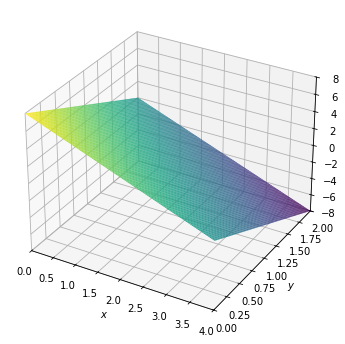

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sympy.plotting import plot3d
plot3d(solve(2*x + 4*y + z - 8, z)[0], (x, 0, 4), (y, 0, 2));
```

</details>

## 6. Lage von Gerade und Ebene

#### Gerade in die Koordinatenform einsetzen

Setzt man die Koordinaten der Geraden g: x = p + t · v in die Koordinatenform von E ein, entsteht eine Gleichung für t:
- genau eine Lösung: g **schneidet** E (Schnittpunkt durch Einsetzen von t in g)
- keine Lösung: g ist **parallel** zu E (fällt t beim Einsetzen weg, zeigt sympy gleich `False` an)
- jedes t ist Lösung (die Gleichung wird zu True): g **liegt in** E

Kontrolle: g ist genau dann parallel zu E oder liegt in E, wenn v · n = 0.

In [ ]:
g = Matrix([1, 0, 2]) + t * Matrix([1, 1, 1])
gl = Eq(6*g[0] + 3*g[1] + 2*g[2], 6)
display(gl)
l = solve(gl, t)
display(l)
g.subs(t, l[0])

#### Aufgabe 6.1

Berechne den Schnittpunkt der Geraden g: x = (0, 0, 1) + t · (1, 2, 1) mit der Ebene E: x + y + z = 9.

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}2\\4\\3\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = Matrix([0, 0, 1]) + t * Matrix([1, 2, 1])
l = solve(Eq(g[0] + g[1] + g[2], 9), t)
g.subs(t, l[0])
```

</details>

#### Aufgabe 6.2

Untersuche die Lage von g: x = (1, 1, 1) + t · (1, −1, 0) und E: x + y + z = 5 (Gleichung für t und Lösung ausgeben).

**Erwartete Ausgabe:**

$\displaystyle \text{False}$

$\displaystyle \left[ \right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = Matrix([1, 1, 1]) + t * Matrix([1, -1, 0])
gl = Eq(g[0] + g[1] + g[2], 5)
display(gl)
solve(gl, t)
```

</details>

#### Aufgabe 6.3

Untersuche die Lage von g: x = (1, 1, 1) + t · (1, −1, 0) und E: x + y + z = 3.

**Erwartete Ausgabe:**

$\displaystyle \text{True}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = Matrix([1, 1, 1]) + t * Matrix([1, -1, 0])
Eq(g[0] + g[1] + g[2], 3)
```

</details>

#### Aufgabe 6.4

Prüfe mit dem Skalarprodukt v · n, ob g: x = (2, 0, 1) + t · (1, 2, 4) parallel zu E: 2x + y − z = 3 ist oder in ihr liegt.

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Matrix([1, 2, 4]).dot(Matrix([2, 1, -1]))
```

</details>

#### Aufgabe 6.5

Berechne den Schnittpunkt der Geraden durch A(1 | 2 | 3) und B(3 | 3 | 1) mit der x-y-Ebene (z = 0).

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}4\\\frac{7}{2}\\0\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
A, B = Matrix([1, 2, 3]), Matrix([3, 3, 1])
g = A + t * (B - A)
g.subs(t, solve(g[2], t)[0])
```

</details>

#### Aufgabe 6.6

Berechne mit `Plane(...).intersection(Line3D(...))` den Schnittpunkt von E: 6x + 3y + 2z = 6 (durch die Spurpunkte gegeben) mit der Geraden durch (0|0|0) und (1|1|1).

**Erwartete Ausgabe:**

$\displaystyle \left[ \operatorname{Point3D}\left(\frac{6}{11}, \frac{6}{11}, \frac{6}{11}\right)\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
E = Plane(Point3D(1, 0, 0), Point3D(0, 2, 0), Point3D(0, 0, 3))
E.intersection(Line3D(Point3D(0, 0, 0), Point3D(1, 1, 1)))
```

</details>

#### Aufgabe 6.7

**Lichtstrahl:** Ein Lichtstrahl geht von L(6 | 2 | 8) in Richtung v = (−2, 1, −4). Wo trifft er die Ebene z = 0 (den Boden)?

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}2\\4\\0\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = Matrix([6, 2, 8]) + t * Matrix([-2, 1, -4])
g.subs(t, solve(g[2], t)[0])
```

</details>

#### Aufgabe 6.8

Für welches a ist die Gerade g: x = (0, 0, 0) + t · (1, a, 2) parallel zur Ebene E: 3x − y + z = 4?

**Erwartete Ausgabe:**

$\displaystyle \left[ 5\right]$

In [ ]:
a = symbols('a', real=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a = symbols('a', real=True)
solve(Matrix([1, a, 2]).dot(Matrix([3, -1, 1])), a)
```

</details>

## 7. Lage zweier Ebenen und Schnittgerade

#### Zwei Koordinatengleichungen als LGS

Zwei Ebenen sind **parallel** oder **identisch**, wenn ihre Normalenvektoren kollinear sind (Kreuzprodukt = Nullvektor). Sonst schneiden sie
sich in einer **Schnittgeraden**. Man findet sie, indem man das LGS aus den beiden Koordinatengleichungen löst: Eine Variable bleibt frei,
sie wird zum Parameter t.

In [ ]:
l = linsolve([Eq(2*x - y + z, 3), Eq(x + y - z, 0)], [x, y, z])
display(l)
g = Matrix(list(l)[0]).subs(z, t)
display(g)
display(g.subs(t, 0), g.diff(t))
Matrix([2, -1, 1]).cross(Matrix([1, 1, -1]))

#### Aufgabe 7.1

Bestimme die Schnittgerade der Ebenen x + y + z = 6 und x − y + 2z = 3 (freie Variable z wird zu t).

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}\frac{9}{2} - \frac{3 t}{2}\\\frac{t}{2} + \frac{3}{2}\\t\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = linsolve([Eq(x + y + z, 6), Eq(x - y + 2*z, 3)], [x, y, z])
Matrix(list(l)[0]).subs(z, t)
```

</details>

#### Aufgabe 7.2

Gib für die Schnittgerade der vorigen Aufgabe den Stützvektor (t = 0) und den Richtungsvektor (`g.diff(t)`) aus.

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}\frac{9}{2}\\\frac{3}{2}\\0\end{matrix}\right]$

$\displaystyle \left[\begin{matrix}- \frac{3}{2}\\\frac{1}{2}\\1\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = Matrix([Rational(9, 2) - 3*t/2, Rational(3, 2) + t/2, t])
display(g.subs(t, 0))
g.diff(t)
```

</details>

#### Aufgabe 7.3

Untersuche, ob die Ebenen 2x − 4y + 6z = 5 und −x + 2y − 3z = 1 parallel sind (Kreuzprodukt der Normalenvektoren) und ob sie gemeinsame Punkte haben (`linsolve`).

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}0\\0\\0\end{matrix}\right]$

$\displaystyle \emptyset$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(Matrix([2, -4, 6]).cross(Matrix([-1, 2, -3])))
linsolve([Eq(2*x - 4*y + 6*z, 5), Eq(-x + 2*y - 3*z, 1)], [x, y, z])
```

</details>

#### Aufgabe 7.4

Untersuche die Ebenen 2x − 4y + 6z = −2 und −x + 2y − 3z = 1 (`linsolve` mit beiden Gleichungen).

**Erwartete Ausgabe:**

$\displaystyle \left\{\left( 2 y - 3 z - 1, \  y, \  z\right)\right\}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
linsolve([Eq(2*x - 4*y + 6*z, -2), Eq(-x + 2*y - 3*z, 1)], [x, y, z])
```

</details>

#### Aufgabe 7.5

Bestimme die Schnittgerade der Ebene 2x + y + z = 4 mit der x-y-Ebene (z = 0). Die freie Variable ist y; setze y = t.

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}2 - \frac{t}{2}\\t\\0\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = linsolve([Eq(2*x + y + z, 4), Eq(z, 0)], [x, y, z])
Matrix(list(l)[0]).subs(y, t)
```

</details>

#### Aufgabe 7.6

Bestimme den Schnittpunkt dreier Ebenen x + y + z = 6, x − y = 1, y − z = −1.

**Erwartete Ausgabe:**

$\displaystyle \left\{\left( \frac{7}{3}, \  \frac{4}{3}, \  \frac{7}{3}\right)\right\}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
linsolve([Eq(x + y + z, 6), Eq(x - y, 1), Eq(y - z, -1)], [x, y, z])
```

</details>

#### Aufgabe 7.7

Berechne die Schnittgerade der Ebenen mit `Plane(...).intersection(Plane(...))` für E₁: x + y + z = 6 (Normalenvektor (1, 1, 1) durch (6 | 0 | 0)) und
E₂: x − y + 2z = 3 (Normalenvektor (1, −1, 2) durch (3 | 0 | 0)).

**Erwartete Ausgabe:**

$\displaystyle \left[ \operatorname{Line3D}\left(\operatorname{Point3D}\left(\frac{9}{2}, \frac{3}{2}, 0\right), \operatorname{Point3D}\left(\frac{15}{2}, \frac{1}{2}, -2\right)\right)\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
E1 = Plane(Point3D(6, 0, 0), normal_vector=(1, 1, 1))
E2 = Plane(Point3D(3, 0, 0), normal_vector=(1, -1, 2))
E1.intersection(E2)
```

</details>

## 8. Gemischte Übungen

#### Aufgabe 8.1

Eine Pyramide hat die Grundfläche A(0 | 0 | 0), B(4 | 0 | 0), C(4 | 4 | 0), D(0 | 4 | 0) und die Spitze S(2 | 2 | 6).
Gib die Koordinatenform der Seitenfläche durch B, C und S aus.

**Erwartete Ausgabe:**

$\displaystyle 24 x + 8 z - 96$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
Plane(Point3D(4, 0, 0), Point3D(4, 4, 0), Point3D(2, 2, 6)).equation(x, y, z)
```

</details>

#### Aufgabe 8.2

Wo trifft die Gerade durch P(0 | 6 | 2) mit dem Richtungsvektor (1, −2, 1) die Ebene der vorigen Aufgabe (3x + z − 12 = 0)?

**Erwartete Ausgabe:**

$\displaystyle \left[\begin{matrix}\frac{5}{2}\\1\\\frac{9}{2}\end{matrix}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = Matrix([0, 6, 2]) + t * Matrix([1, -2, 1])
g.subs(t, solve(3*g[0] + g[2] - 12, t)[0])
```

</details>

#### Aufgabe 8.3

Für welches a liegt der Punkt P(1 | a | 2) in der Ebene durch A(1 | 0 | 0), B(0 | 1 | 0), C(0 | 0 | 1)?

**Erwartete Ausgabe:**

$\displaystyle \left[ -2\right]$

In [ ]:
a = symbols('a', real=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a = symbols('a', real=True)
e = Plane(Point3D(1, 0, 0), Point3D(0, 1, 0), Point3D(0, 0, 1)).equation(x, y, z)
solve(e.subs({x: 1, y: a, z: 2}), a)
```

</details>

#### Aufgabe 8.4

Gegeben ist die Ebenenschar Eₐ: a·x + y + z = 2. Für welches a ist Eₐ parallel zur Geraden g: x = t · (1, 2, 3)? Für welches a enthält Eₐ den Punkt (1 | 1 | 1)?

**Erwartete Ausgabe:**

$\displaystyle \left[ -5\right]$

$\displaystyle \left[ 0\right]$

In [ ]:
a = symbols('a', real=True)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a = symbols('a', real=True)
display(solve(Matrix([a, 1, 1]).dot(Matrix([1, 2, 3])), a))
solve(a + 1 + 1 - 2, a)
```

</details>

#### Aufgabe 8.5

Prüfe, ob die vier Punkte A(1 | 0 | 0), B(0 | 2 | 0), C(0 | 0 | 3) und D(1 | 2 | −3) in einer Ebene liegen (Ebene durch A, B, C, dann D einsetzen).

**Erwartete Ausgabe:**

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
e = Plane(Point3D(1, 0, 0), Point3D(0, 2, 0), Point3D(0, 0, 3)).equation(x, y, z)
e.subs({x: 1, y: 2, z: -3}) == 0
```

</details>